<a href="https://colab.research.google.com/github/Rafikyop/telecom-customer-churn-prediction/blob/main/CarlosGuillermo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install xgboost

In [ ]:
# Basic libraries
import os
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from xgboost import XGBClassifier

# Display configuration
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_DIR = Path("/content/drive/MyDrive/Final Assignment")
DATA_DIR = BASE_DIR / "telecom"

client_path = DATA_DIR / "Client.csv"
record_path = DATA_DIR / "Record.csv"

print("Client path:", client_path)
print("Record path:", record_path)

print("Client exists:", client_path.exists())
print("Record exists:", record_path.exists())

Client path: /content/drive/MyDrive/Final Assignment/telecom/Client.csv
Record path: /content/drive/MyDrive/Final Assignment/telecom/Record.csv
Client exists: True
Record exists: True


In [ ]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print("Client shape:", client.shape)
print("Record shape:", record.shape)

display(client.head())
display(record.head())

Client shape: (100000, 50)
Record shape: (100000, 51)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [ ]:
print("Client columns:")
print(client.columns.tolist())

print("\nRecord columns:")
print(record.columns.tolist())

Client columns:
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID']

Record columns:
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'in

In [ ]:
df = pd.merge(client, record, on="Customer_ID", how="inner")

print("Merged dataset shape:", df.shape)
display(df.head())

Merged dataset shape: (100000, 100)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


In [ ]:
print("Dataset information:")
df.info()

print("\nBasic statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 100 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   uniqsubs          100000 non-null  int64  
 1   actvsubs          100000 non-null  int64  
 2   new_cell          100000 non-null  object 
 3   crclscod          100000 non-null  object 
 4   asl_flag          100000 non-null  object 
 5   totcalls          100000 non-null  int64  
 6   totmou            100000 non-null  float64
 7   totrev            100000 non-null  float64
 8   adjrev            100000 non-null  float64
 9   adjmou            100000 non-null  float64
 10  adjqty            100000 non-null  int64  
 11  avgrev            100000 non-null  float64
 12  avgmou            100000 non-null  float64
 13  avgqty            100000 non-null  float64
 14  avg3mou           100000 non-null  int64  
 15  avg3qty           100000 non-null  int64  
 16 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
uniqsubs,100000.0,NaN,NaN,NaN,1.54814,1.075255,1.0,1.0,1.0,2.0,196.0
actvsubs,100000.0,NaN,NaN,NaN,1.35896,0.655555,0.0,1.0,1.0,2.0,53.0
new_cell,100000,3,U,66914,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crclscod,100000,54,AA,36509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
asl_flag,100000,2,N,86064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
totcalls,100000.0,NaN,NaN,NaN,2877.14193,3790.863474,0.0,889.0,1822.0,3492.0,98874.0
totmou,100000.0,NaN,NaN,NaN,7648.363833,8666.558293,0.0,2529.0,5191.5,9776.0,233419.0967
totrev,100000.0,NaN,NaN,NaN,1031.924988,852.907511,3.65,518.98,804.53,1263.7675,27321.5
adjrev,100000.0,NaN,NaN,NaN,960.111528,840.170815,2.4,452.18,737.76,1188.175,27071.3
adjmou,100000.0,NaN,NaN,NaN,7546.314699,8594.889729,0.0,2474.0,5102.5,9661.0,232855.1


In [ ]:
print("Churn value counts:")
display(df["churn"].value_counts())

print("\nChurn percentage:")
display(df["churn"].value_counts(normalize=True).mul(100).round(2))

Churn value counts:


,count
churn,
0,50438
1,49562



Churn percentage:


,proportion
churn,
0,50.44
1,49.56


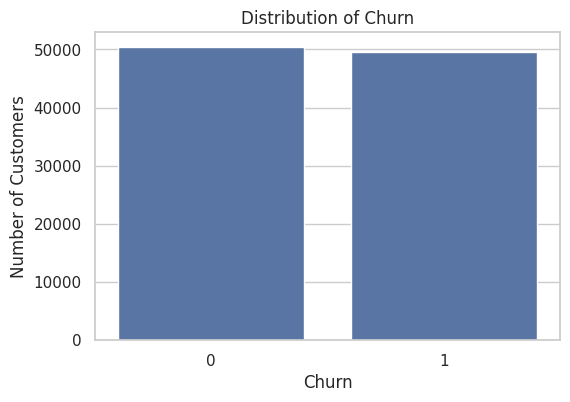

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="churn")
plt.title("Distribution of Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

**The target variable is churn. It indicates whether a customer left the company or not.
The distribution is important because it tells us whether the classification problem is balanced or imbalanced.**

In [ ]:
# Check missing values
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percent": missing_percent
})

missing_summary = missing_summary[missing_summary["missing_count"] > 0]

display(missing_summary.head(30))

,missing_count,missing_percent
numbcars,49366,49.366
dwllsize,38308,38.308
HHstatin,37923,37.923
ownrent,33706,33.706
dwlltype,31909,31.909
lor,30190,30.190
income,25436,25.436
adults,23019,23.019
infobase,22079,22.079
hnd_webcap,10189,10.189


###**Missing Values Analysis**

The dataset contains missing values in several variables. Missing values are expected in customer behavior datasets because not every service, device attribute, or billing characteristic is available for every customer.

For the machine learning model, missing numerical values will be imputed using the median, while missing categorical values will be filled with a "Missing" category. This allows us to keep as many customers as possible instead of dropping rows and losing information.

### **Missing Values Insight**

Several demographic and household-related variables contain a high percentage of missing values. For example, variables such as number of cars, dwelling size, home ownership, income, and household status have substantial missingness.

Because dropping these rows would remove a large portion of the customer base, the model will preserve these observations and handle missing values during preprocessing. Numerical variables will be imputed with the median, while categorical variables will be imputed with a "Missing" category.

From a business perspective, this also suggests that the company may not have complete customer profile data, which can limit personalization. A future recommendation is to improve customer data collection during onboarding and service interactions.

In [ ]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Number of numeric columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nNumeric columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Number of numeric columns: 79
Number of categorical columns: 21

Numeric columns:
['uniqsubs', 'actvsubs', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'hnd_price', 'phones', 'models', 'truck', 'rv', 'lor', 'adults', 'income', 'numbcars', 'forgntvl', 'eqpdays', 'Customer_ID', 'rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_M

In [ ]:
# Numeric summary by churn
numeric_summary_by_churn = df.groupby("churn")[numeric_cols].mean().T

numeric_summary_by_churn.columns = ["No Churn Mean", "Churn Mean"]
numeric_summary_by_churn["Difference"] = (
    numeric_summary_by_churn["Churn Mean"] - numeric_summary_by_churn["No Churn Mean"]
)

numeric_summary_by_churn["Abs Difference"] = numeric_summary_by_churn["Difference"].abs()

display(
    numeric_summary_by_churn
    .sort_values("Abs Difference", ascending=False)
    .head(20)
)

,No Churn Mean,Churn Mean,Difference,Abs Difference
Customer_ID,1.051224e+06,1.048755e+06,-2469.097153,2469.097153
adjmou,7.695686e+03,7.394304e+03,-301.381752,301.381752
totmou,7.793975e+03,7.500179e+03,-293.796661,293.796661
adjqty,2.896912e+03,2.774752e+03,-122.159346,122.159346
totcalls,2.936440e+03,2.816796e+03,-119.643435,119.643435
mou_Mean,5.432069e+02,4.833064e+02,-59.900478,59.900478
eqpdays,3.632809e+02,4.210895e+02,57.808600,57.808600
avg3mou,5.458501e+02,4.929691e+02,-52.880964,52.880964
avg6mou,5.314451e+02,4.876795e+02,-43.765657,43.765657
mou_cvce_Mean,2.414035e+02,2.138825e+02,-27.520948,27.520948


In [ ]:
important_numeric_features = [
    "eqpdays",
    "months",
    "mou_Mean",
    "rev_Mean",
    "totmrc_Mean",
    "change_mou",
    "change_rev",
    "hnd_price",
    "phones",
    "uniqsubs"
]

# Keep only columns that actually exist in the dataset
important_numeric_features = [col for col in important_numeric_features if col in df.columns]

important_numeric_features

['eqpdays',
 'months',
 'mou_Mean',
 'rev_Mean',
 'totmrc_Mean',
 'change_mou',
 'change_rev',
 'hnd_price',
 'phones',
 'uniqsubs']

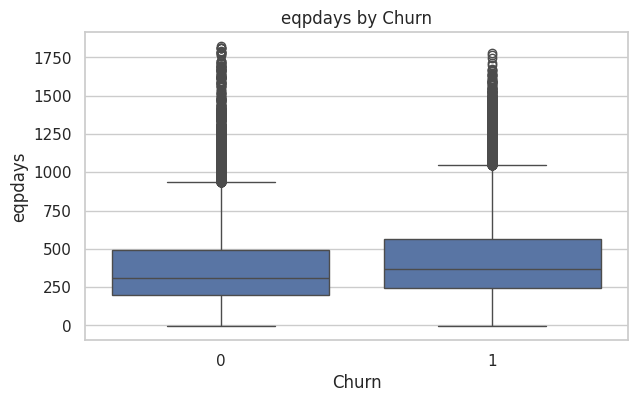

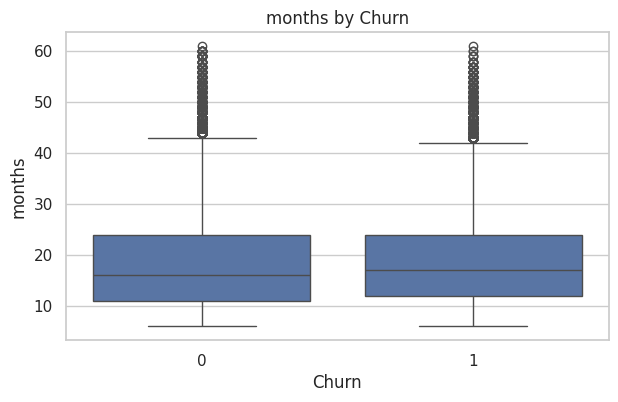

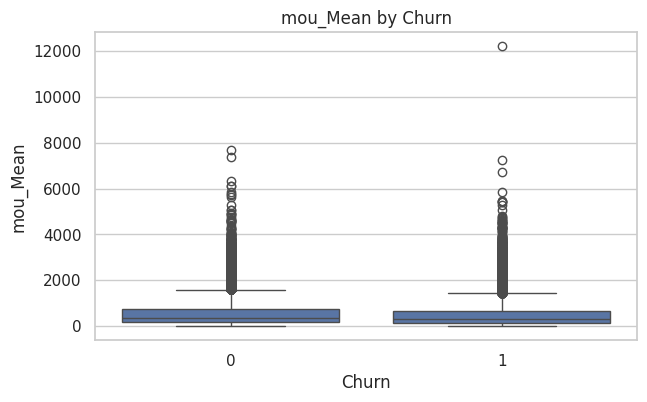

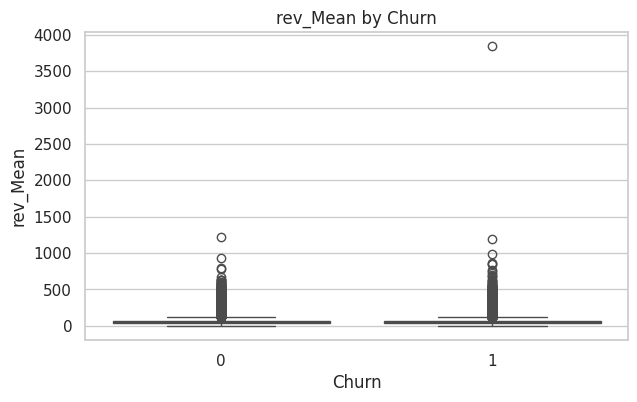

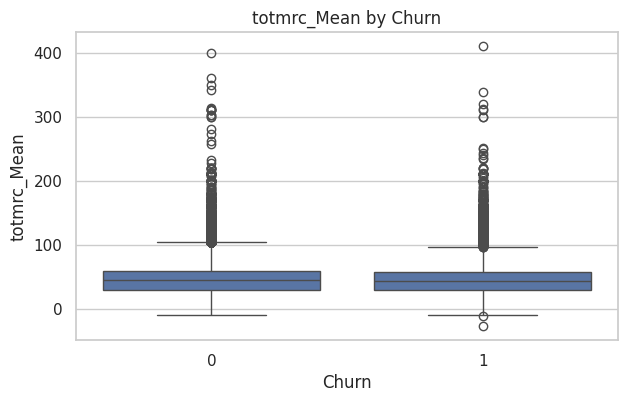

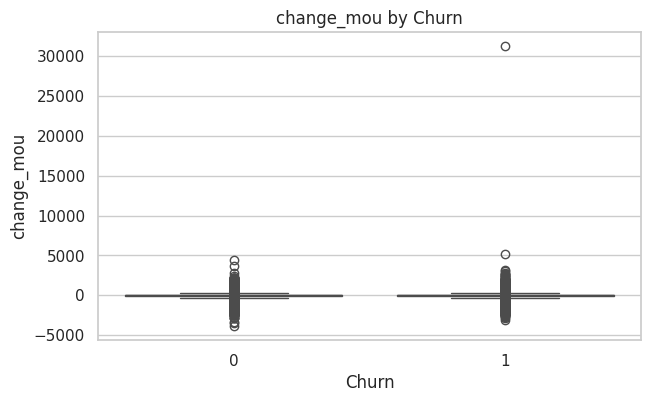

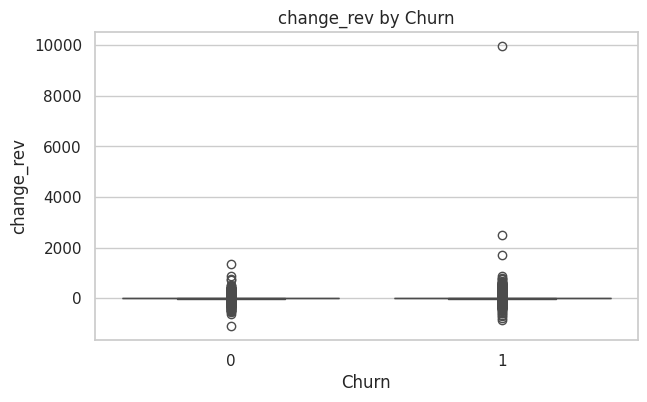

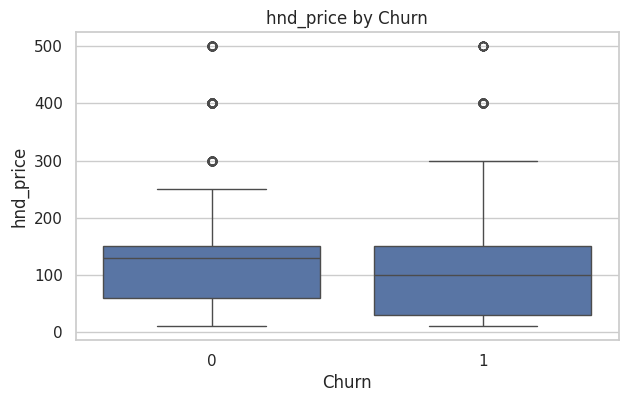

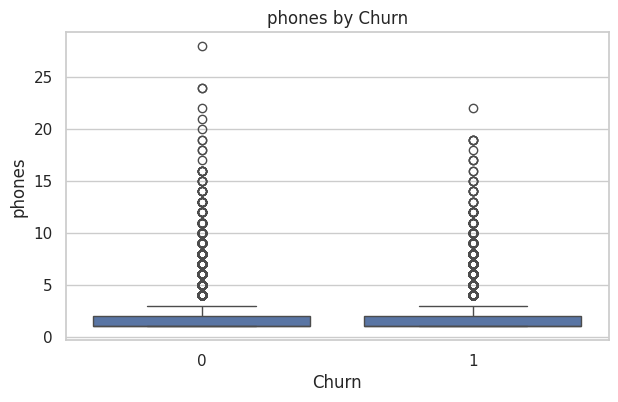

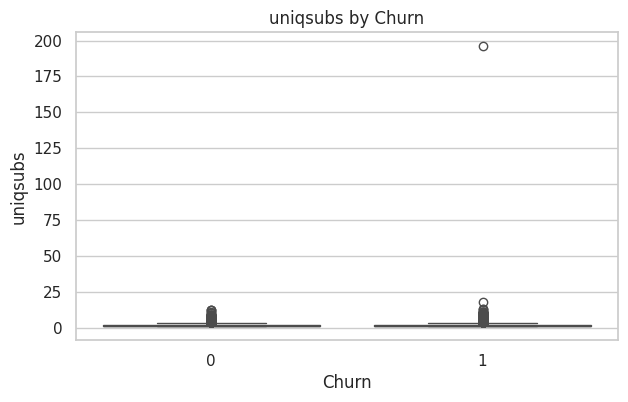

In [ ]:
for col in important_numeric_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="churn", y=col)
    plt.title(f"{col} by Churn")
    plt.xlabel("Churn")
    plt.ylabel(col)
    plt.show()

In [ ]:
median_comparison = df.groupby("churn")[important_numeric_features].median().T
median_comparison.columns = ["No Churn Median", "Churn Median"]
median_comparison["Difference"] = median_comparison["Churn Median"] - median_comparison["No Churn Median"]

display(median_comparison)

,No Churn Median,Churn Median,Difference
eqpdays,310.00000,366.00000,56.00000
months,16.00000,17.00000,1.00000
mou_Mean,380.50000,329.75000,-50.75000
rev_Mean,48.87625,47.49000,-1.38625
totmrc_Mean,44.99000,43.41750,-1.57250
change_mou,-3.00000,-10.00000,-7.00000
change_rev,-0.29250,-0.31500,-0.02250
hnd_price,129.98999,99.98999,-30.00000
phones,1.00000,1.00000,0.00000
uniqsubs,1.00000,1.00000,0.00000


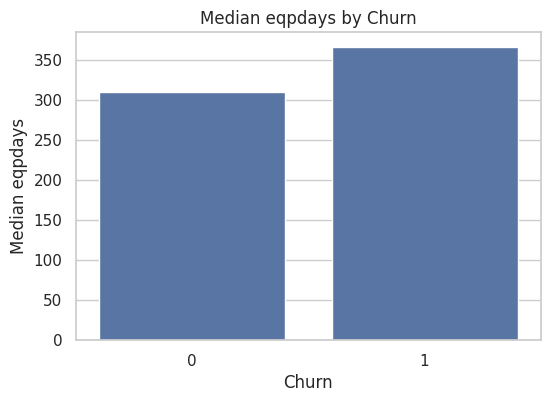

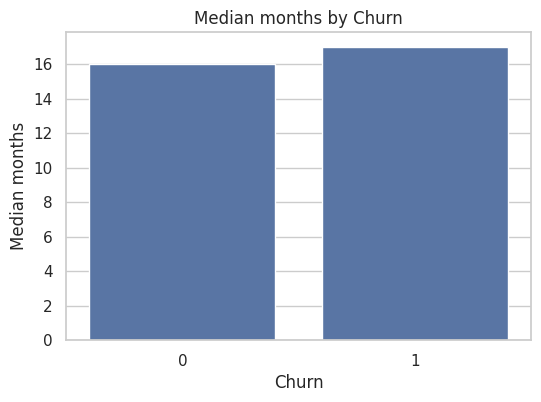

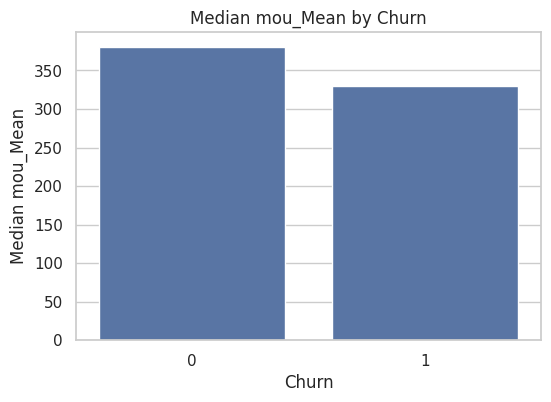

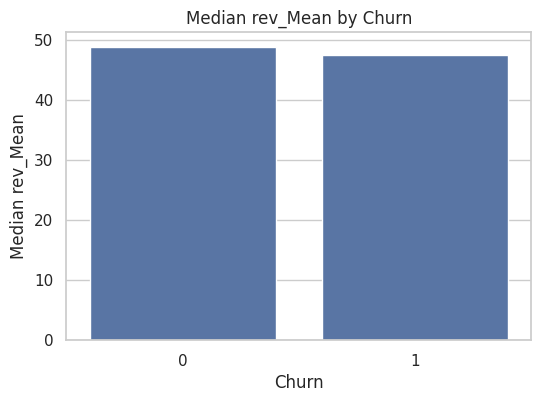

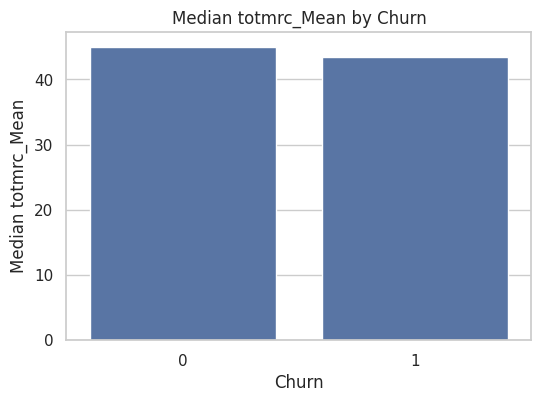

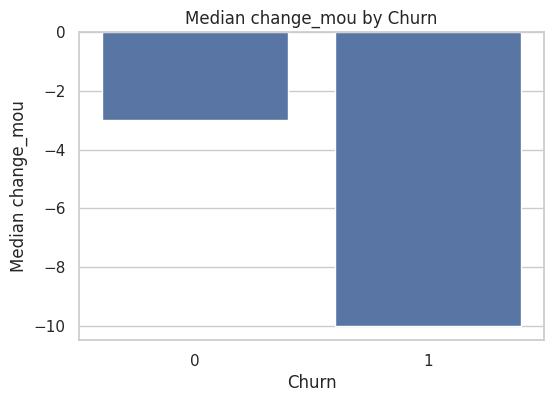

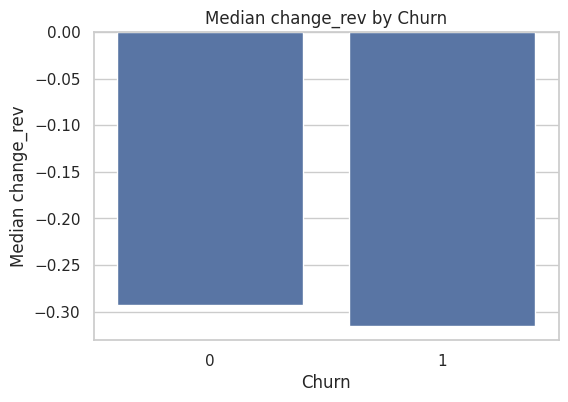

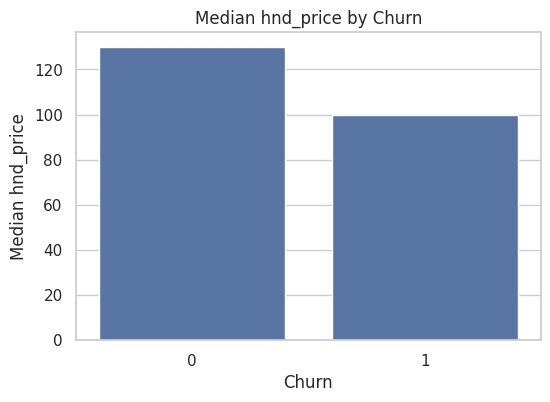

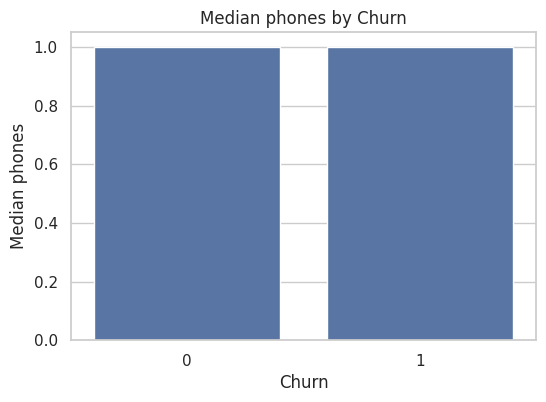

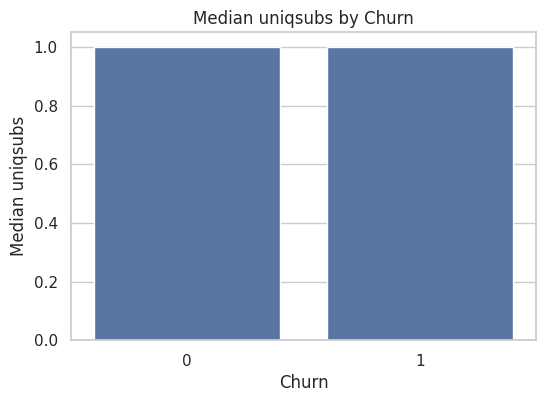

In [ ]:
for col in important_numeric_features:
    temp = df.groupby("churn")[col].median().reset_index()

    plt.figure(figsize=(6, 4))
    sns.barplot(data=temp, x="churn", y=col)
    plt.title(f"Median {col} by Churn")
    plt.xlabel("Churn")
    plt.ylabel(f"Median {col}")
    plt.show()

In [ ]:
categorical_cols

['new_cell',
 'crclscod',
 'asl_flag',
 'prizm_social_one',
 'area',
 'dualband',
 'refurb_new',
 'hnd_webcap',
 'ownrent',
 'dwlltype',
 'marital',
 'infobase',
 'HHstatin',
 'dwllsize',
 'ethnic',
 'kid0_2',
 'kid3_5',
 'kid6_10',
 'kid11_15',
 'kid16_17',
 'creditcd']

In [ ]:
for col in categorical_cols:
    print(f"\nChurn rate by {col}")

    churn_by_category = (
        df.groupby(col)["churn"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )

    churn_by_category["mean"] = churn_by_category["mean"] * 100
    churn_by_category = churn_by_category.rename(columns={"mean": "churn_rate_percent"})

    display(churn_by_category.head(10))


Churn rate by new_cell


,count,churn_rate_percent
new_cell,,
U,66914,49.695131
N,13785,49.662677
Y,19301,49.028548



Churn rate by crclscod


,count,churn_rate_percent
crclscod,,
V,1,100.000000
TP,5,80.000000
A3,3,66.666667
P1,6,66.666667
A2,861,61.556330
Y,54,59.259259
Z1,12,58.333333
EM,57,57.894737
JF,194,57.731959



Churn rate by asl_flag


,count,churn_rate_percent
asl_flag,,
N,86064,50.959751
Y,13936,40.929966


... (32 outputs left out)


Churn rate by kid16_17


,count,churn_rate_percent
kid16_17,,
Y,9964,50.220795
U,88304,49.520973



Churn rate by creditcd


,count,churn_rate_percent
creditcd,,
N,31034,50.828124
Y,67234,49.021328


In [ ]:
selected_categorical_features = [
    "refurb_new",
    "hnd_webcap",
    "asl_flag",
    "ownrent",
    "dwlltype",
    "marital",
    "infobase"
]

selected_categorical_features = [col for col in selected_categorical_features if col in df.columns]

selected_categorical_features

['refurb_new',
 'hnd_webcap',
 'asl_flag',
 'ownrent',
 'dwlltype',
 'marital',
 'infobase']

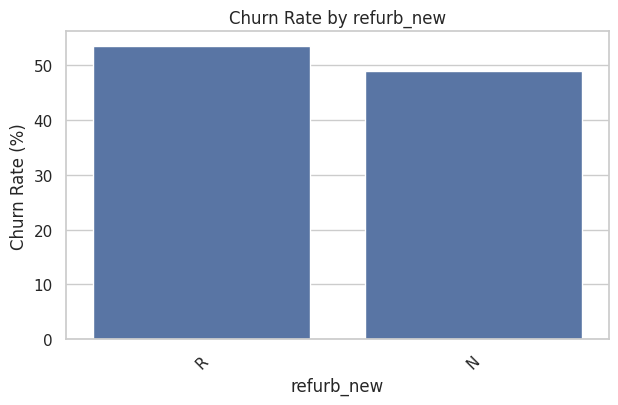

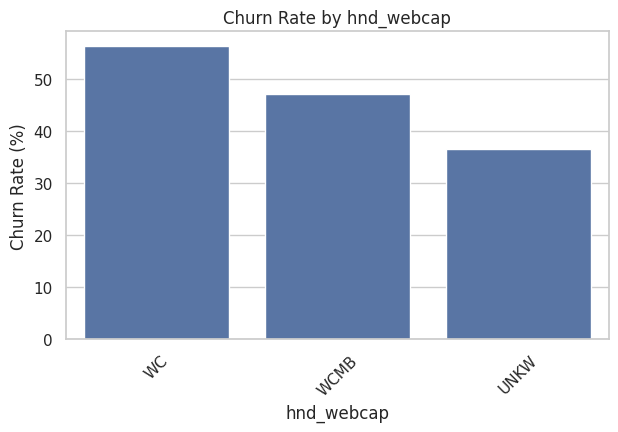

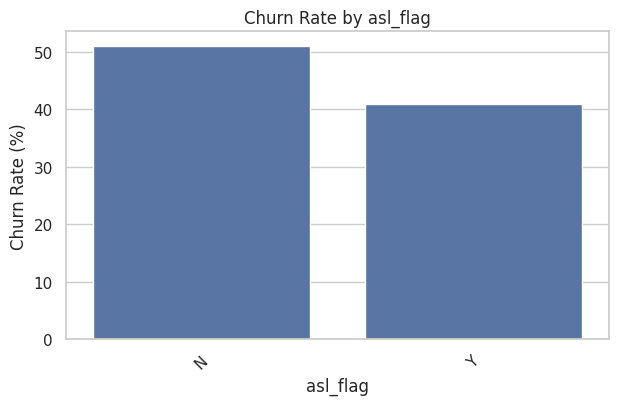

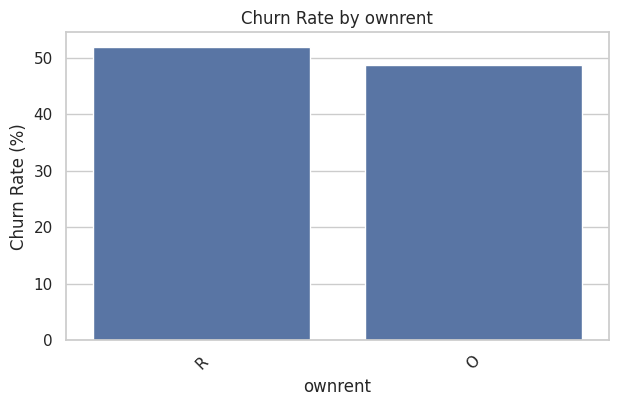

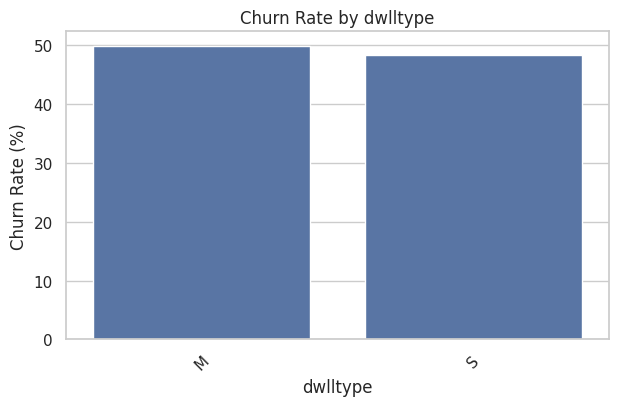

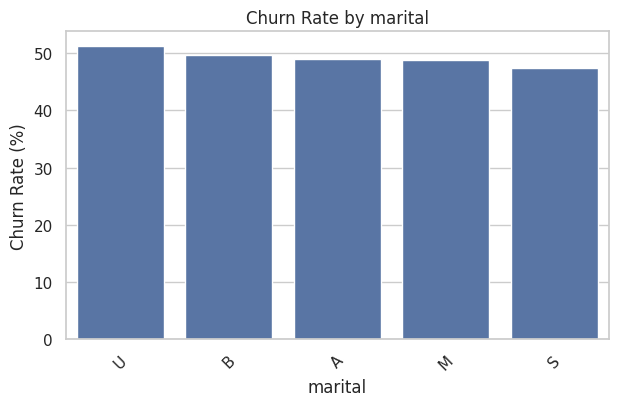

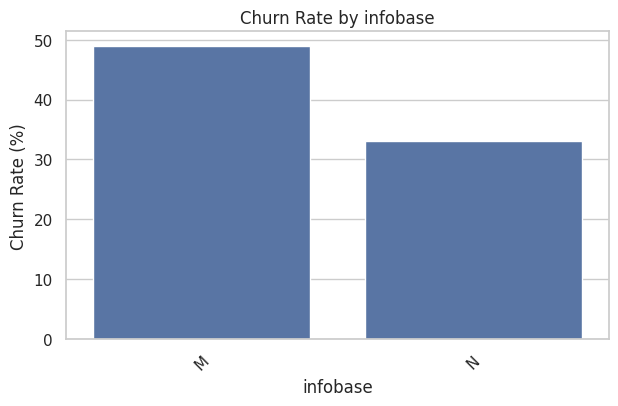

In [ ]:
for col in selected_categorical_features:
    temp = (
        df.groupby(col)["churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .reset_index()
    )

    plt.figure(figsize=(7, 4))
    sns.barplot(data=temp, x=col, y="churn")
    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=45)
    plt.show()

In [ ]:
correlation_with_churn = (
    df[numeric_cols]
    .corr(numeric_only=True)["churn"]
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

display(correlation_with_churn.head(20))

,churn
churn,1.000000
eqpdays,0.112691
hnd_price,-0.103184
totmrc_Mean,-0.068558
mou_Mean,-0.057027
mou_cvce_Mean,-0.052042
complete_Mean,-0.051740
comp_vce_Mean,-0.051574
avg3mou,-0.049546
mou_opkv_Mean,-0.048896


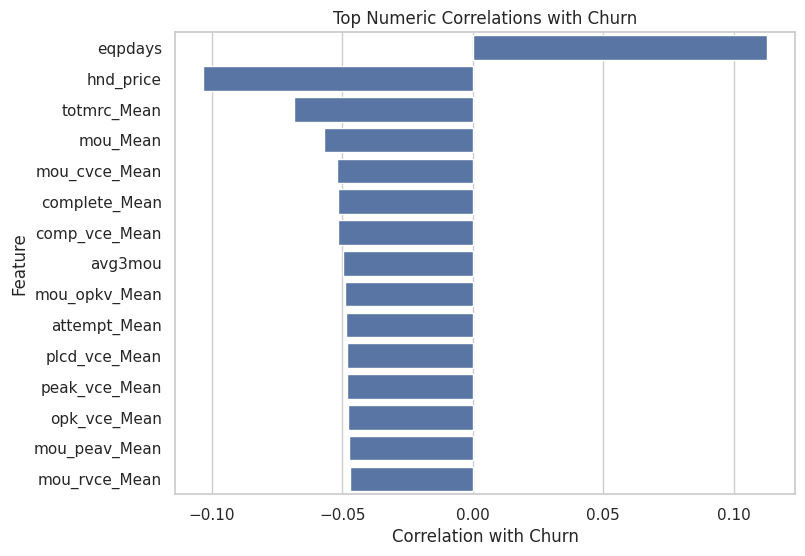

In [ ]:
top_corr = correlation_with_churn.drop("churn").head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_corr.values, y=top_corr.index)
plt.title("Top Numeric Correlations with Churn")
plt.xlabel("Correlation with Churn")
plt.ylabel("Feature")
plt.show()

##**Business Hypothesis**

Based on the initial EDA, customer churn appears to be related to customer tenure, device characteristics, usage behavior, and changes in recent activity.

The main business hypothesis is:

Customers with older devices, weaker engagement, or declining usage are more likely to churn. Therefore, the company can reduce churn by identifying high-risk customers and offering targeted retention actions such as device upgrades, plan optimization, or proactive customer support.

This hypothesis will be tested using a machine learning model that predicts the probability of churn for each customer.

### **EDA Insight 1: Older Devices Are Associated with Higher Churn**

Customers who churn have older devices on average. The median number of equipment days is 366 for churned customers compared with 310 for non-churned customers.

This suggests that customers with older devices may be more likely to leave, possibly because they are dissatisfied with device performance, looking for a better handset offer, or considering competitor upgrade promotions.

Business implication: the company should prioritize device upgrade offers for high-risk customers with older equipment.

### **EDA Insight 2: Lower Usage Is Associated with Churn**

Customers who churn have lower median monthly usage. The median value of `mou_Mean` is 329.75 for churned customers, compared with 380.50 for non-churned customers.

This indicates that declining or low engagement may be an early warning signal. Customers who are no longer using the service heavily may be more likely to switch providers.

Business implication: the company should monitor usage decline and trigger proactive retention actions before the customer leaves.

### **EDA Insight 3: Usage Decline Is a Warning Signal**

The median `change_mou` is -10 for churned customers and -3 for non-churned customers. This means that customers who churn tend to show a stronger recent decline in usage.

This is important because usage decline can be detected before churn happens. The company can use this signal to intervene earlier.

Business implication: customers with sharp drops in usage should be included in the high-priority retention segment.

### **EDA Insight 4: Lower Handset Price Is Associated with Higher Churn**

Churned customers have a lower median handset price. The median `hnd_price` is 99.99 for churned customers, compared with 129.99 for non-churned customers.

This may indicate that customers with lower-end devices are more price-sensitive, less attached to the service, or more likely to respond to competitor promotions.

Business implication: retention offers should not be the same for all customers. Device-based and price-sensitive offers may be more effective for this segment.

## E**DA Conclusion**

The exploratory analysis suggests that churn is not random. Several behavioral and device-related variables show meaningful differences between churned and non-churned customers.

Key churn signals include:

1. Older equipment age (`eqpdays`)
2. Lower monthly usage (`mou_Mean`)
3. Stronger recent usage decline (`change_mou`)
4. Lower handset price (`hnd_price`)
5. Slightly lower monthly recurring charge and revenue variables

These findings support the business hypothesis that churn can be predicted using customer behavior, device characteristics, and recent usage changes.

Therefore, the next step is to build a machine learning model that estimates churn probability for each customer. The model will be used to prioritize retention actions toward customers with the highest predicted risk.

In [ ]:
# Define target and features
target = "churn"

# Drop target and customer identifier from features
X = df.drop(columns=[target, "Customer_ID"])
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature matrix shape: (100000, 98)
Target shape: (100000,)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,57


,churn
0,1
1,0
2,1
3,0
4,0


In [ ]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical features:")
print(categorical_features)

Numeric features: 77
Categorical features: 21

Categorical features:
['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("y_test distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

X_train: (70000, 98)
X_test: (30000, 98)
y_train distribution:


,proportion
churn,
0,50.44
1,49.56


y_test distribution:


,proportion
churn,
0,50.44
1,49.56


In [ ]:
# Preprocessing for numerical variables:
# Missing values are replaced with the median.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical variables:
# Missing values are replaced with "Missing", then categories are one-hot encoded.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
])

# Combine preprocessing steps
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.90,
    colsample_bytree=0.90,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

clf = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", xgb_model)
])

clf

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['uniqsubs', 'actvsubs',
                                                   'totcalls', 'totmou',
                                                   'totrev', 'adjrev', 'adjmou',
                                                   'adjqty', 'avgrev', 'avgmou',
                                                   'avgqty', 'avg3mou',
                                                   'avg3qty', 'avg3rev',
                                                   'avg6mou', 'avg6qty',
                                                   'avg6rev', 'hnd_price',
                                                   'phones', 'models', 'truck',
                                                   'rv', 'lor', 'ad...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
clf.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['uniqsubs', 'actvsubs',
                                                   'totcalls', 'totmou',
                                                   'totrev', 'adjrev', 'adjmou',
                                                   'adjqty', 'avgrev', 'avgmou',
                                                   'avgqty', 'avg3mou',
                                                   'avg3qty', 'avg3rev',
                                                   'avg6mou', 'avg6qty',
                                                   'avg6rev', 'hnd_price',
                                                   'phones', 'models', 'truck',
                                                   'rv', 'lor', 'ad...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
# Predictions
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "ROC-AUC", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, roc_auc, precision, recall, f1]
})

display(metrics_summary)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

,Metric,Score
0,Accuracy,0.633867
1,ROC-AUC,0.687870
2,Precision,0.623702
3,Recall,0.658686
4,F1-score,0.640717



Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.61      0.63     15131
           1       0.62      0.66      0.64     14869

    accuracy                           0.63     30000
   macro avg       0.63      0.63      0.63     30000
weighted avg       0.63      0.63      0.63     30000



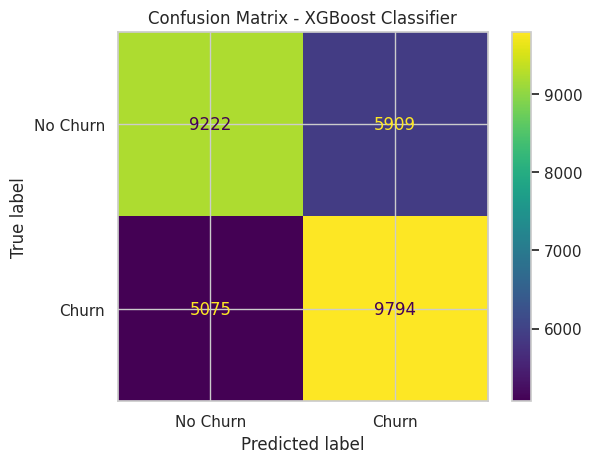

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - XGBoost Classifier")
plt.show()

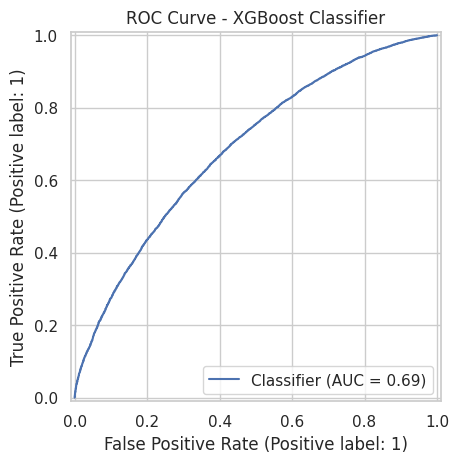

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve - XGBoost Classifier")
plt.show()

## **Model Evaluation**

The selected model is an XGBoost Classifier. This model was chosen because it can capture non-linear relationships between customer behavior, device characteristics, billing variables, and churn.

The main evaluation metric is ROC-AUC because the business goal is not only to classify customers as churn or no churn, but also to rank customers by churn risk. This ranking is useful for prioritizing retention campaigns.

Additional metrics such as accuracy, precision, recall, and F1-score are also reported to provide a more complete view of model performance.

## **Model Results Interpretation**

The XGBoost Classifier achieved the following performance on the test set:

- Accuracy: 0.6339
- ROC-AUC: 0.6879
- Precision: 0.6237
- Recall: 0.6587
- F1-score: 0.6407

The ROC-AUC score of 0.6879 indicates that the model has meaningful ability to rank customers by churn risk. This is especially useful for a retention strategy because the company does not need to perfectly classify every customer; instead, it needs to prioritize the customers with the highest probability of leaving.

The recall score of 0.6587 means that the model captures approximately 65.9% of actual churn customers in the test set. From a business perspective, this is valuable because missing a churn customer may result in lost recurring revenue.

The confusion matrix shows that the model correctly identified 9,794 churn customers, while 5,075 churn customers were missed. It also incorrectly flagged 5,909 non-churn customers as churn. This tradeoff is acceptable for a PoC because retention campaigns can be designed with relatively low-cost interventions, such as targeted offers, plan reviews, or proactive support calls.

In [ ]:
# Get feature names after preprocessing

preprocessor = clf.named_steps["preprocess"]
model = clf.named_steps["model"]

# Numeric feature names
num_feature_names = numeric_features

# Categorical feature names after one-hot encoding
cat_feature_names = (
    preprocessor
    .named_transformers_["cat"]
    .named_steps["onehot"]
    .get_feature_names_out(categorical_features)
    .tolist()
)

all_feature_names = num_feature_names + cat_feature_names

print("Number of transformed features:", len(all_feature_names))
print("Number of model importances:", len(model.feature_importances_))

Number of transformed features: 226
Number of model importances: 226


In [ ]:
feature_importance = pd.DataFrame({
    "feature": all_feature_names,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values("importance", ascending=False)

display(feature_importance.head(25))

,feature,importance
27,eqpdays,0.053806
146,refurb_new_R,0.043325
145,refurb_new_N,0.029455
76,months,0.023361
156,dwlltype_Missing,0.019928
151,hnd_webcap_WCMB,0.018919
17,hnd_price,0.016422
173,HHstatin_Missing,0.014389
29,mou_Mean,0.013787
165,infobase_Missing,0.012618


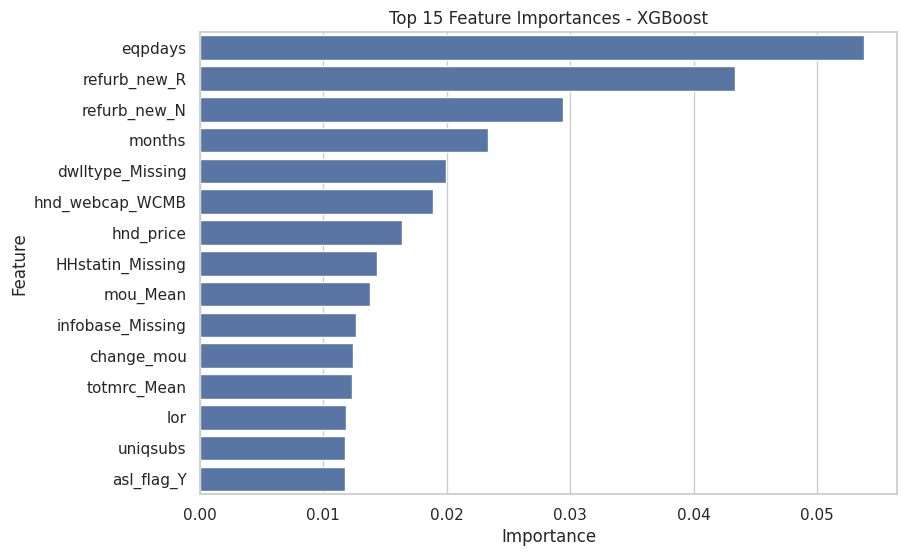

In [ ]:
top_n = 15

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance.head(top_n),
    x="importance",
    y="feature"
)
plt.title("Top 15 Feature Importances - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## **Feature Importance Interpretation**

The feature importance analysis shows which variables contributed most to the XGBoost model's churn predictions.

The most relevant variables are expected to include customer tenure, equipment age, device characteristics, usage behavior, and billing-related variables. This is consistent with the EDA findings, where churned customers showed older equipment, lower usage, stronger usage decline, and lower handset price.

From a business perspective, these features are actionable. The company can design retention actions based on customer behavior and device status, rather than applying the same generic campaign to all customers.

In [ ]:
# Create a test results table with churn probability

test_results = X_test.copy()
test_results["actual_churn"] = y_test.values
test_results["predicted_churn"] = y_pred
test_results["churn_probability"] = y_proba

display(test_results[["actual_churn", "predicted_churn", "churn_probability"]].head())

,actual_churn,predicted_churn,churn_probability
87134,0,0,0.241811
85408,0,1,0.595368
17864,0,1,0.601013
70586,0,0,0.461240
84231,0,1,0.586471


In [ ]:
# Select top 20% highest-risk customers
target_share = 0.20
cutoff = test_results["churn_probability"].quantile(1 - target_share)

test_results["high_risk_segment"] = (
    test_results["churn_probability"] >= cutoff
).astype(int)

print("Probability cutoff for top 20%:", cutoff)

display(test_results["high_risk_segment"].value_counts())

Probability cutoff for top 20%: 0.6115974664688111


,count
high_risk_segment,
0,24000
1,6000


In [ ]:
risk_segment_summary = (
    test_results
    .groupby("high_risk_segment")["actual_churn"]
    .agg(["count", "mean"])
    .reset_index()
)

risk_segment_summary["churn_rate_percent"] = risk_segment_summary["mean"] * 100

risk_segment_summary["segment"] = risk_segment_summary["high_risk_segment"].map({
    0: "Other customers",
    1: "Top 20% high-risk customers"
})

display(risk_segment_summary[["segment", "count", "churn_rate_percent"]])

,segment,count,churn_rate_percent
0,Other customers,24000,43.854167
1,Top 20% high-risk customers,6000,72.400000


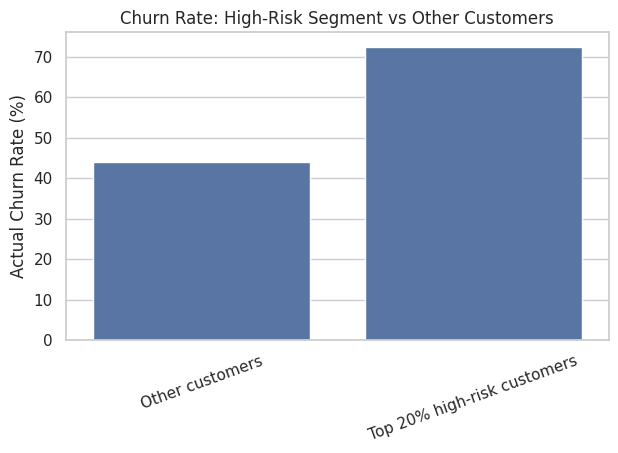

In [ ]:
plt.figure(figsize=(7, 4))
sns.barplot(
    data=risk_segment_summary,
    x="segment",
    y="churn_rate_percent"
)
plt.title("Churn Rate: High-Risk Segment vs Other Customers")
plt.xlabel("")
plt.ylabel("Actual Churn Rate (%)")
plt.xticks(rotation=20)
plt.show()

In [ ]:
# Business impact assumptions

# Average monthly revenue among high-risk customers
avg_monthly_revenue = test_results.loc[
    test_results["high_risk_segment"] == 1,
    "rev_Mean"
].mean()

# Number of targeted customers in the test set
targeted_customers = test_results["high_risk_segment"].sum()

# Actual churners in the targeted group
actual_churners_targeted = test_results.loc[
    test_results["high_risk_segment"] == 1,
    "actual_churn"
].sum()

# Assumptions for the retention campaign
intervention_cost_per_customer = 15
save_rate = 0.15
months_saved = 6

# Estimated saved customers
estimated_saved_customers = actual_churners_targeted * save_rate

# Revenue retained
estimated_retained_revenue = estimated_saved_customers * avg_monthly_revenue * months_saved

# Campaign cost
campaign_cost = targeted_customers * intervention_cost_per_customer

# Net impact
net_impact = estimated_retained_revenue - campaign_cost

business_impact = pd.DataFrame({
    "Metric": [
        "Targeted customers",
        "Actual churners in targeted group",
        "Average monthly revenue per targeted customer",
        "Assumed save rate",
        "Months of revenue protected",
        "Estimated saved customers",
        "Estimated retained revenue",
        "Campaign cost",
        "Estimated net impact"
    ],
    "Value": [
        targeted_customers,
        actual_churners_targeted,
        avg_monthly_revenue,
        save_rate,
        months_saved,
        estimated_saved_customers,
        estimated_retained_revenue,
        campaign_cost,
        net_impact
    ]
})

display(business_impact)

,Metric,Value
0,Targeted customers,6000.000000
1,Actual churners in targeted group,4344.000000
2,Average monthly revenue per targeted customer,54.609274
3,Assumed save rate,0.150000
4,Months of revenue protected,6.000000
5,Estimated saved customers,651.600000
6,Estimated retained revenue,213500.416519
7,Campaign cost,90000.000000
8,Estimated net impact,123500.416519


In [ ]:
business_impact_formatted = business_impact.copy()

def format_value(x):
    if isinstance(x, (int, float, np.integer, np.floating)):
        return f"{x:,.2f}"
    return x

business_impact_formatted["Value"] = business_impact_formatted["Value"].apply(format_value)

display(business_impact_formatted)

,Metric,Value
0,Targeted customers,"6,000.00"
1,Actual churners in targeted group,"4,344.00"
2,Average monthly revenue per targeted customer,54.61
3,Assumed save rate,0.15
4,Months of revenue protected,6.00
5,Estimated saved customers,651.60
6,Estimated retained revenue,"213,500.42"
7,Campaign cost,"90,000.00"
8,Estimated net impact,"123,500.42"


## **Business Proposal**

Based on the EDA and machine learning results, the proposed solution is a Predictive Retention Program for high-risk telecom customers.

The model will score each customer based on churn probability. The company should prioritize the top 20% highest-risk customers and offer targeted retention actions, such as:

1. Device upgrade offers for customers with older equipment.
2. Plan optimization for customers with declining usage.
3. Personalized discounts for price-sensitive customers.
4. Proactive customer support for customers showing engagement decline.

This approach is better than a mass campaign because it concentrates retention spending on customers with higher churn risk. The model allows the company to reduce wasted incentives and protect recurring revenue.

## **Estimated Business Impact**

The business impact calculation estimates the potential financial benefit of targeting the top 20% highest-risk customers.

The assumptions used are:

- Intervention cost per customer: 15 USD
- Save rate: 15%
- Revenue protection period: 6 months

Using these assumptions, the campaign estimates how many churn customers could be retained, how much revenue could be protected, and whether the expected retained revenue exceeds the cost of the campaign.

This calculation is not a final financial forecast. It is a PoC-level estimate that shows the potential value of using machine learning to prioritize retention actions.

## **Feature Importance Interpretation**

The feature importance results show that the model relies mainly on device-related, tenure-related, usage-related, and billing-related variables.

The most important variable is `eqpdays`, which confirms the EDA finding that customers with older devices are more likely to churn. Device condition variables such as `refurb_new` and `hnd_price` are also highly relevant, suggesting that handset quality and value are important drivers of retention.

Customer behavior variables such as `mou_Mean` and `change_mou` also contribute meaningfully to churn prediction. This indicates that lower usage and recent declines in usage are strong warning signals.

Some missing-value indicators from categorical variables also appear among the top features. This suggests that certain customer segments with incomplete profile information may behave differently and may deserve closer investigation.

Overall, the model findings are consistent with the EDA and support the idea that churn can be predicted and acted upon using customer behavior, device status, and recent engagement changes.

## **High-Risk Segment Interpretation**

To translate the model into a business action, customers were ranked by predicted churn probability. The top 20% highest-risk customers were defined as the priority retention segment.

This segment contains 6,000 customers in the test sample. Its actual churn rate is 72.4%, compared with 43.85% for the remaining customers.

This result shows that the model successfully concentrates churn risk in the high-risk segment. Therefore, the company can use the model to focus retention resources on a smaller group of customers with much higher expected churn, instead of applying generic campaigns to the entire customer base.

## **Business Proposal**

The recommended business proposal is a Predictive Retention Program for high-risk telecom customers.

The company should score customers using the churn prediction model and prioritize the top 20% highest-risk customers for intervention. The intervention strategy should be tailored to the main churn signals identified in the analysis:

1. Device upgrade or renewal offers for customers with older equipment.
2. Plan review or usage-based plan optimization for customers with low or declining usage.
3. Personalized retention offers for customers with lower handset value or stronger price sensitivity.
4. Proactive customer support or outreach for customers showing early disengagement.

This approach is more efficient than a mass retention campaign because it uses data to focus spending on customers with the highest probability of leaving.

## **Estimated Business Impact**

A business impact simulation was conducted using the top 20% high-risk segment.

Assumptions:
- Intervention cost per customer: 15 USD
- Save rate: 15%
- Revenue protection period: 6 months

Results:
- Targeted customers: 6,000
- Actual churners in targeted group: 4,344
- Estimated saved customers: 651.6
- Estimated retained revenue: 213,500.42 USD
- Campaign cost: 90,000.00 USD
- Estimated net impact: 123,500.42 USD

This simulation suggests that a targeted retention campaign can generate positive financial value. While this is a PoC-level estimate and depends on assumptions, it demonstrates that machine learning can support a meaningful business case for customer retention.

## **Final Conclusion**

This project shows that telecom customer churn can be meaningfully predicted using customer behavior, device information, and billing-related variables.

The EDA identified clear patterns: churned customers tend to have older devices, lower usage, stronger usage decline, and lower handset price. The XGBoost model achieved an ROC-AUC of 0.6879 and successfully identified a high-risk segment with a 72.4% actual churn rate.

Based on these findings, the recommended strategy is a predictive retention program focused on the top 20% highest-risk customers. Under reasonable assumptions, this strategy can produce positive net financial impact.

The next step for the client would be to test this program in a real pilot campaign, measure retention uplift, and refine the intervention strategy using campaign response data.